In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 12.7 MB/s eta 0:00:00


In [ ]:
!pip install albumentations

In [ ]:
import kagglehub
import os
from google.colab import userdata
import json
from datetime import datetime
# import zipfile
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import train_test_split
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import WeightedRandomSampler
import seaborn as sns
import random
from torch.cuda.amp import GradScaler, autocast

In [ ]:
timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

In [ ]:
TRAINING_CONFIG = {
    'model_name': 'Segformer',
    'encoder_name': 'mit_b2',
    'encoder_weights': 'imagenet',
    'batch_size_train': 16,
    'batch_size_val': 8,
    'batch_size_test': 8,
    'num_workers_train': 2,
    'num_workers_val': 2,
    'num_workers_test': 2,
    'num_epochs': 80,
    'patience': 20,
    'learning_rate': 3e-4,
    'weight_decay': 1e-5,
    'threshold': 0.5
}

In [ ]:
"""
def denormalize(tensor, mean, std):
    mean = torch.tensor(mean).view(-1, 1, 1)
    std = torch.tensor(std).view(-1, 1, 1)
    return tensor * std + mean
"""

'\ndef denormalize(tensor, mean, std):\n    mean = torch.tensor(mean).view(-1, 1, 1)\n    std = torch.tensor(std).view(-1, 1, 1)\n    return tensor * std + mean\n'

In [ ]:
"""
zip_path = '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/open-bio-2024-final-project.zip'
extract_path = '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
"""

"\nzip_path = '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/open-bio-2024-final-project.zip'\nextract_path = '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/'\n\nwith zipfile.ZipFile(zip_path, 'r') as zip_ref:\n    zip_ref.extractall(extract_path)\n"

In [ ]:
train_fold = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/train/data/train.csv")
print(f"Loaded training data with {len(train_fold)} samples")

Loaded training data with 1744 samples


In [ ]:
train_fold.head()

,id,organ,data_source,img_height,img_width,pixel_size,tissue_thickness,age,sex,image_path,mask_path,slice_id
0,10274,prostate,HPA,512,512,0.4,4,76.0,Male,data/train/10274_0003.png,data/masks/10274_0003.png,10274_0003
1,10274,prostate,HPA,512,512,0.4,4,76.0,Male,data/train/10274_0001.png,data/masks/10274_0001.png,10274_0001
2,10274,prostate,HPA,512,512,0.4,4,76.0,Male,data/train/10274_0004.png,data/masks/10274_0004.png,10274_0004
3,10274,prostate,HPA,512,512,0.4,4,76.0,Male,data/train/10274_0000.png,data/masks/10274_0000.png,10274_0000
4,10274,prostate,HPA,512,512,0.4,4,76.0,Male,data/train/10274_0006.png,data/masks/10274_0006.png,10274_0006


In [ ]:
train_fold[['image_path', 'mask_path']].head()

,image_path,mask_path
0,data/train/10274_0003.png,data/masks/10274_0003.png
1,data/train/10274_0001.png,data/masks/10274_0001.png
2,data/train/10274_0004.png,data/masks/10274_0004.png
3,data/train/10274_0000.png,data/masks/10274_0000.png
4,data/train/10274_0006.png,data/masks/10274_0006.png


In [ ]:
train_fold['image_path'] = train_fold['image_path'].str.replace('data/train/', '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/train/data/train/')
train_fold['mask_path'] = train_fold['mask_path'].str.replace('data/masks/', '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/train/data/masks/')


In [ ]:
train_fold.head()

,id,organ,data_source,img_height,img_width,pixel_size,tissue_thickness,age,sex,image_path,mask_path,slice_id
0,10274,prostate,HPA,512,512,0.4,4,76.0,Male,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,10274_0003
1,10274,prostate,HPA,512,512,0.4,4,76.0,Male,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,10274_0001
2,10274,prostate,HPA,512,512,0.4,4,76.0,Male,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,10274_0004
3,10274,prostate,HPA,512,512,0.4,4,76.0,Male,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,10274_0000
4,10274,prostate,HPA,512,512,0.4,4,76.0,Male,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,10274_0006


In [ ]:
print(os.path.exists(train_fold.loc[0, 'image_path']))
print(os.path.exists(train_fold.loc[0, 'mask_path']))

True
True


In [ ]:
train_df_before_cleaning = train_fold.copy()

bad_indices = [
    1, 7, 47, 51, 60, 61, 65, 70, 74, 86, 105, 112, 118,
    175, 193, 247, 248, 278, 286, 432, 475, 477, 479, 518, 556,
    601, 747, 751, 1033, 1042, 1095, 1115, 1145, 1151, 1161,
    1170, 1173, 1175, 1201, 1371
]

bad_rows = train_fold.loc[bad_indices, ["id", "organ", "slice_id", "image_path", "mask_path"]]

print(bad_rows["organ"].value_counts())
# display(bad_rows[bad_rows["organ"] == "lung"])

organ
prostate          11
kidney            11
spleen             9
largeintestine     9
Name: count, dtype: int64


In [ ]:
train_fold = train_fold.reset_index(drop=True)

print("Before cleaning:", len(train_fold))

bad_rows = train_fold.loc[bad_indices, ["id", "organ", "slice_id", "image_path", "mask_path"]]
display(bad_rows.head())

train_fold = train_fold.drop(index=bad_indices).reset_index(drop=True)

print("After cleaning:", len(train_fold))


patient_df = train_fold[["id", "organ"]].drop_duplicates(subset="id").reset_index(drop=True)

train_patients, val_patients = train_test_split(
    patient_df,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=patient_df["organ"]
)

train_ids = set(train_patients["id"])
val_ids = set(val_patients["id"])

train_df = train_fold[train_fold["id"].isin(train_ids)].reset_index(drop=True)
val_df = train_fold[train_fold["id"].isin(val_ids)].reset_index(drop=True)

patient_overlap = set(train_df["id"]) & set(val_df["id"])

print("Training set size:", len(train_df))
print("Validation set size:", len(val_df))
print("Train patients:", train_df["id"].nunique())
print("Val patients:", val_df["id"].nunique())
print("Patient overlap:", len(patient_overlap))

Before cleaning: 1744


,id,organ,slice_id,image_path,mask_path
1,10274,prostate,10274_0001,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...
7,10274,prostate,10274_0005,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...
47,10703,spleen,10703_0001,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...
51,10912,prostate,10912_0001,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...
60,10971,prostate,10971_0004,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...


After cleaning: 1704
Training set size: 1367
Validation set size: 337
Train patients: 168
Val patients: 42
Patient overlap: 0


In [ ]:
multi_organ_patients = train_fold.groupby("id")["organ"].nunique()
print((multi_organ_patients > 1).sum())

0


In [ ]:
len(set(train_df['image_path']) & set(val_df['image_path']))

0

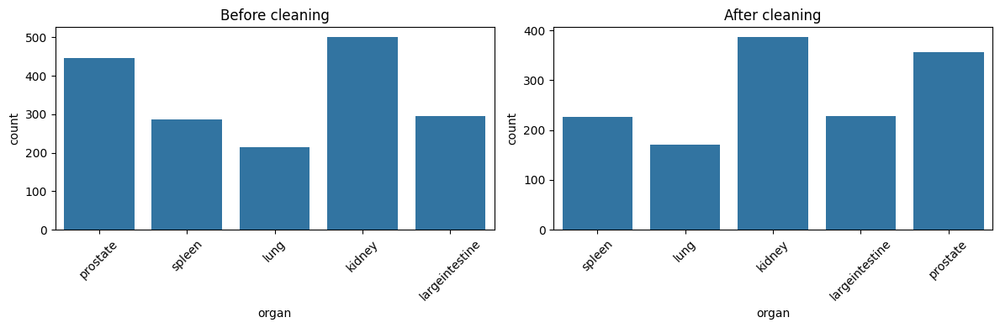

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=train_df_before_cleaning, x='organ', ax=axes[0])
axes[0].set_title("Before cleaning")
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(data=train_df, x='organ', ax=axes[1])
axes[1].set_title("After cleaning")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
print(train_df["organ"].value_counts())

organ
kidney            387
prostate          356
largeintestine    228
spleen            226
lung              170
Name: count, dtype: int64


In [ ]:
"""
def has_mask_pixels(mask_path):
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    return mask.sum() > 0

train_df["has_mask"] = train_df["mask_path"].apply(has_mask_pixels)

print(train_df["has_mask"].value_counts())
print(train_df["has_mask"].value_counts(normalize=True))

pd.crosstab(train_df["organ"], train_df["has_mask"])
"""

'\ndef has_mask_pixels(mask_path):\n    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)\n    return mask.sum() > 0\n\ntrain_df["has_mask"] = train_df["mask_path"].apply(has_mask_pixels)\n\nprint(train_df["has_mask"].value_counts())\nprint(train_df["has_mask"].value_counts(normalize=True))\n\npd.crosstab(train_df["organ"], train_df["has_mask"])\n'

In [ ]:
"""
sns.countplot(data=train_df, x="organ", hue="has_mask")
plt.title("Empty vs non-empty masks by organ")
plt.xticks(rotation=45)
plt.show()
"""

'\nsns.countplot(data=train_df, x="organ", hue="has_mask")\nplt.title("Empty vs non-empty masks by organ")\nplt.xticks(rotation=45)\nplt.show()\n'

In [ ]:
"""
positive_pixels = 0
total_pixels = 0

for mask_path in train_df["mask_path"]:
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    mask_bool = mask > 0

    positive_pixels += mask_bool.sum()
    total_pixels += mask_bool.size

negative_pixels = total_pixels - positive_pixels
pos_weight_value = negative_pixels / positive_pixels

print("Positive pixel fraction:", positive_pixels / total_pixels)
print("Recommended pos_weight:", pos_weight_value)
"""

'\npositive_pixels = 0\ntotal_pixels = 0\n\nfor mask_path in train_df["mask_path"]:\n    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)\n    mask_bool = mask > 0\n\n    positive_pixels += mask_bool.sum()\n    total_pixels += mask_bool.size\n\nnegative_pixels = total_pixels - positive_pixels\npos_weight_value = negative_pixels / positive_pixels\n\nprint("Positive pixel fraction:", positive_pixels / total_pixels)\nprint("Recommended pos_weight:", pos_weight_value)\n'

Patient id: 12483
Number of images: 9
Organs: ['spleen']



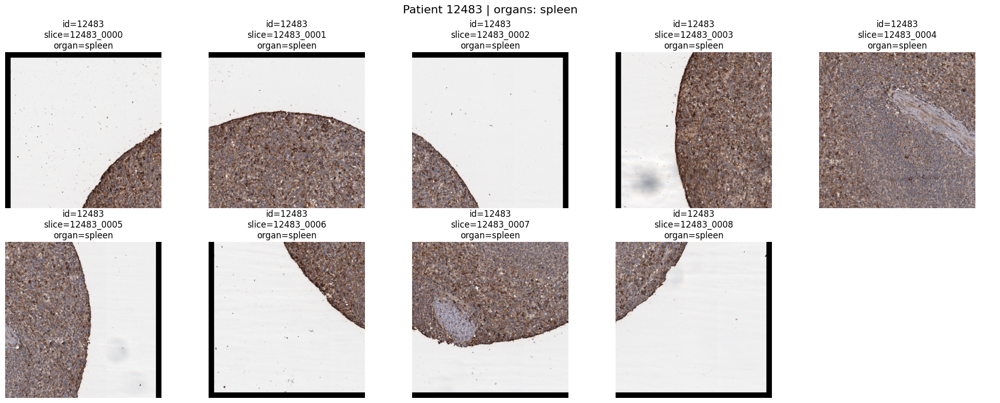

Patient id: 3303
Number of images: 8
Organs: ['largeintestine']



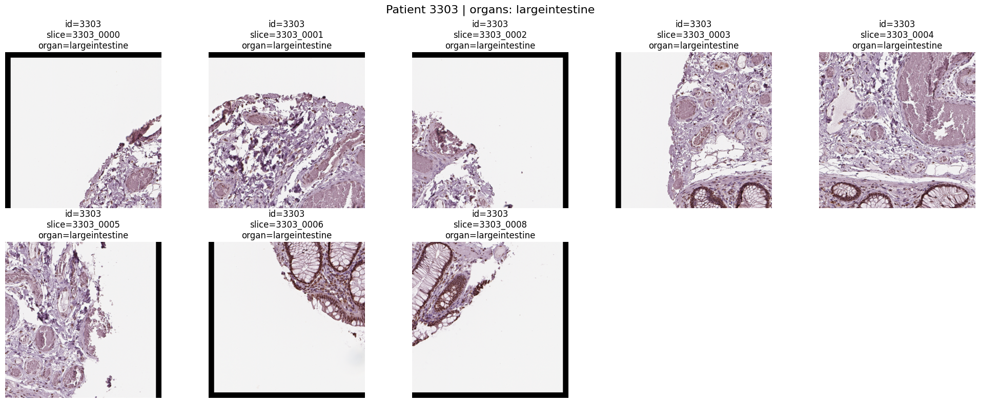

Patient id: 8638
Number of images: 9
Organs: ['prostate']



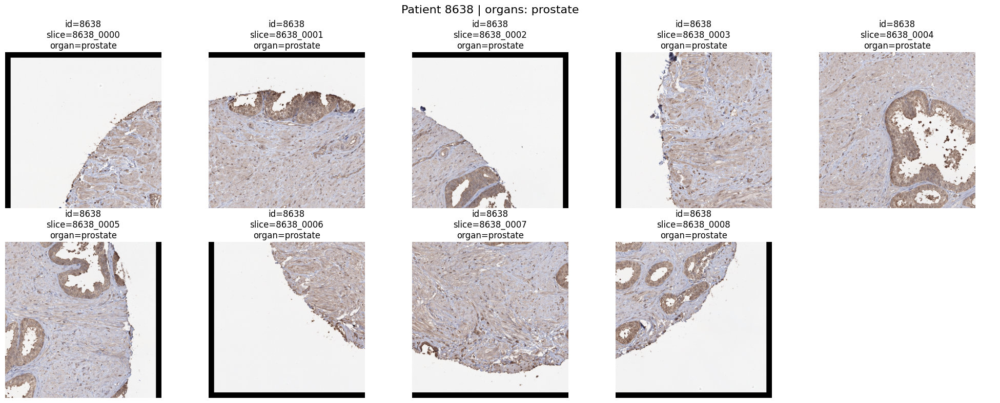

Patient id: 21021
Number of images: 9
Organs: ['kidney']



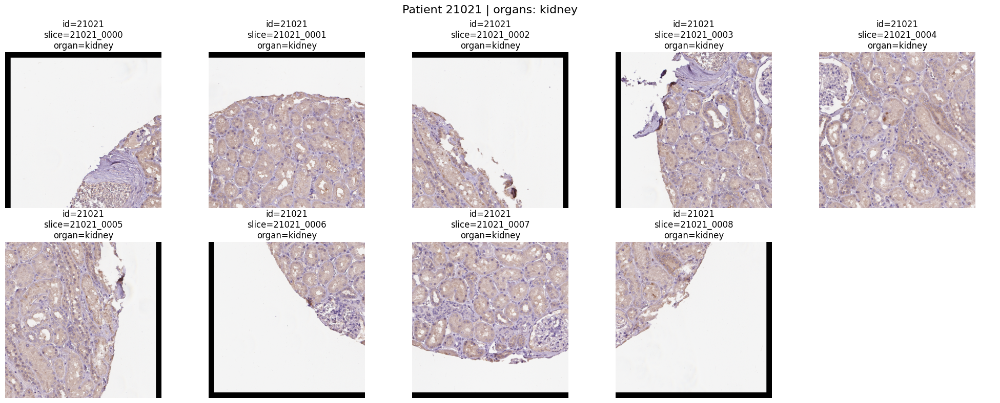

In [ ]:
df = train_df

patient_ids = random.sample(list(df["id"].unique()), 4)

for patient_id in patient_ids:
    patient_df = df[df["id"] == patient_id].copy()

    patient_df["slice_index"] = patient_df["slice_id"].str.split("_").str[1].astype(int)
    patient_df = patient_df.sort_values("slice_index").reset_index(drop=True)

    organs = patient_df["organ"].unique()
    print(f"Patient id: {patient_id}")
    print(f"Number of images: {len(patient_df)}")
    print(f"Organs: {organs}")
    print()

    n_images = len(patient_df)
    n_cols = min(5, n_images)
    n_rows = math.ceil(n_images / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))

    if n_rows == 1 and n_cols == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, row in patient_df.iterrows():
        image = cv2.imread(row["image_path"], cv2.IMREAD_UNCHANGED)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        axes[i].imshow(image)
        axes[i].set_title(
            f"id={row['id']}\n"
            f"slice={row['slice_id']}\n"
            f"organ={row['organ']}"
        )
        axes[i].axis("off")

    for j in range(n_images, len(axes)):
        axes[j].axis("off")

    plt.suptitle(f"Patient {patient_id} | organs: {', '.join(organs)}", fontsize=16)
    plt.tight_layout()
    plt.show()

In [ ]:
# Compute IoU (Jaccard) between predictions and masks
def compute_iou(preds, masks, threshold=TRAINING_CONFIG['threshold']):
    preds = (preds > threshold).float()
    intersection = (preds * masks).sum(dim=(1, 2, 3))
    union = ((preds + masks) >= 1).float().sum(dim=(1, 2, 3))
    iou = (intersection + 1e-6) / (union + 1e-6)
    return iou.mean().item()

In [ ]:
# Evaluate model and return average IoU
def evaluate_model(model, dataloader, device, threshold=TRAINING_CONFIG['threshold']):
    model.eval()
    iou_scores = []

    with torch.inference_mode():
        for batch in tqdm(dataloader, desc="Evaluating"):
            images = batch[0].to(device)
            masks = batch[1].to(device)

            with torch.amp.autocast(device_type='cuda' if device.type == 'cuda' else 'cpu'):
                outputs = model(images)
                preds = torch.sigmoid(outputs)

            iou = compute_iou(preds, masks, threshold)
            iou_scores.append(iou)

    return np.mean(iou_scores)

In [ ]:
class SegmentationDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "image_path"]
        mask_path = self.df.loc[idx, "mask_path"]

        # Load images
        image = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Apply Albumentations transform
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]
            mask = (mask > 0).float()  # Mask binarization

        mask = mask.unsqueeze(0)
        return image, mask

In [ ]:
"""
class SimpleCombinedLoss(nn.Module):
    def __init__(self):
        super(SimpleCombinedLoss, self).__init__()
        self.dice_loss = smp.losses.DiceLoss(mode='binary')
        # self.bce_loss = smp.losses.SoftBCEWithLogitsLoss()
        self.bce_loss = smp.losses.SoftBCEWithLogitsLoss(pos_weight=torch.tensor([10.0]).to(device))

    def forward(self, outputs, targets):
        dice = self.dice_loss(outputs, targets)
        bce = self.bce_loss(outputs, targets)
        return 0.7 * dice + 0.3 * bce
"""

"\nclass SimpleCombinedLoss(nn.Module):\n    def __init__(self):\n        super(SimpleCombinedLoss, self).__init__()\n        self.dice_loss = smp.losses.DiceLoss(mode='binary')\n        # self.bce_loss = smp.losses.SoftBCEWithLogitsLoss()\n        self.bce_loss = smp.losses.SoftBCEWithLogitsLoss(pos_weight=torch.tensor([10.0]).to(device))\n\n    def forward(self, outputs, targets):\n        dice = self.dice_loss(outputs, targets)\n        bce = self.bce_loss(outputs, targets)\n        return 0.7 * dice + 0.3 * bce\n"

In [ ]:
class SimpleCombinedLoss(nn.Module):
    def __init__(self):
        super().__init__()

        self.lovasz_loss = smp.losses.LovaszLoss(
            mode="binary",
            per_image=True,
            from_logits=True,
        )

        self.bce_loss = smp.losses.SoftBCEWithLogitsLoss(
            pos_weight=torch.tensor([10.0], device=device)
        )

    def forward(self, outputs, targets):
        lovasz = self.lovasz_loss(outputs, targets)
        bce = self.bce_loss(outputs, targets)

        return 0.7 * lovasz + 0.3 * bce

In [ ]:
# Mean: [0.7756168  0.75037868 0.76858318]
# Std: [0.22779241 0.2376828  0.23061448]

In [ ]:
# Train transforms
train_transform = A.Compose([
    A.HorizontalFlip(p=0.2),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.2),
    A.GaussianBlur(blur_limit=3, p=0.05),
    A.Affine(scale=(0.9, 1.0), rotate=0, translate_percent=0, shear=0, p=0.25, mode=cv2.BORDER_CONSTANT, cval=0, cval_mask=0),
    A.GaussNoise(var_limit=(5.0, 25.0), p=0.15),
    # A.Normalize(mean=(0.7756168, 0.75037868, 0.76858318), std=(0.22779241, 0.2376828, 0.23061448)),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Validation transforms
val_transform = A.Compose([
    # A.Normalize(mean=(0.7756168, 0.75037868, 0.76858318), std=(0.22779241, 0.2376828, 0.23061448)),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Test transforms
test_transform = A.Compose([
    # A.Normalize(mean=(0.7756168, 0.75037868, 0.76858318), std=(0.22779241, 0.2376828, 0.23061448)),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

/tmp/ipykernel_7249/2608191199.py:6: UserWarning: Argument(s) 'mode, cval, cval_mask' are not valid for transform Affine
  A.Affine(scale=(0.9, 1.0), rotate=0, translate_percent=0, shear=0, p=0.25, mode=cv2.BORDER_CONSTANT, cval=0, cval_mask=0),
/tmp/ipykernel_7249/2608191199.py:7: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 25.0), p=0.15),


In [ ]:
train_dataset = SegmentationDataset(dataframe=train_df, transform=train_transform)
val_dataset = SegmentationDataset(dataframe=val_df, transform=val_transform)

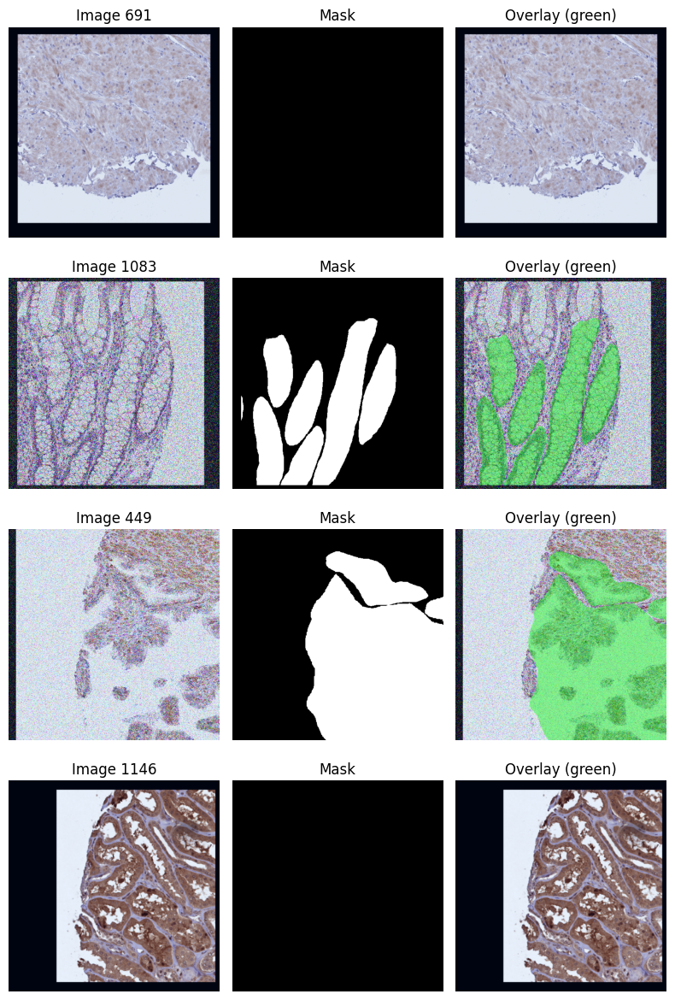

In [ ]:
n = 4
indices = random.sample(range(len(train_dataset)), n)

plt.figure(figsize=(8, n * 3))

for i, idx in enumerate(indices):
    img, mask = train_dataset[idx]

    img_np = img.permute(1, 2, 0).cpu().numpy()
    mask_np = mask.squeeze().cpu().numpy()

    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

    overlay = img_np.copy()

    color = np.array([0.0, 1.0, 0.0])
    alpha = 0.4
    mask_bool = mask_np > 0

    overlay[mask_bool] = (
        (1 - alpha) * overlay[mask_bool] + alpha * color
    )

    plt.subplot(n, 3, 3 * i + 1)
    plt.imshow(img_np)
    plt.title(f"Image {idx}")
    plt.axis("off")

    plt.subplot(n, 3, 3 * i + 2)
    plt.imshow(mask_np, cmap="gray")
    plt.title("Mask")
    plt.axis("off")

    plt.subplot(n, 3, 3 * i + 3)
    plt.imshow(overlay)
    plt.title("Overlay (green)")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
mean_pos = train_dataset[0][1].mean().item()
print("Average mask fill:", mean_pos)

Average mask fill: 0.0103302001953125


In [ ]:
train_dataset[0]

(tensor([[[-2.1179, -0.7822, -2.1179,  ..., -1.0390, -2.1179, -2.1179],
          [-1.4158, -2.1179, -2.1179,  ..., -2.1179, -0.7137, -0.7993],
          [-2.1179, -0.5424, -0.7993,  ..., -2.1179, -0.5596, -1.2103],
          ...,
          [-2.1179, -2.1179, -0.8678,  ...,  0.3652,  0.1939,  2.2489],
          [-2.1179,  1.5468, -2.1179,  ..., -2.1179, -2.1179,  2.2489],
          [-1.7925, -2.1179, -2.1179,  ..., -2.1179, -1.0048,  2.2489]],
 
         [[-0.6001, -2.0357, -2.0357,  ..., -0.0399, -1.1604, -0.7052],
          [ 0.6954, -2.0357, -0.9328,  ...,  1.1856, -1.1078, -2.0357],
          [-2.0357, -0.2150, -0.0924,  ..., -2.0357, -2.0357, -2.0357],
          ...,
          [-2.0357, -0.0224, -2.0357,  ..., -1.0553, -0.6001, -0.0749],
          [-1.3179, -2.0357, -1.0728,  ..., -0.8803, -1.5630,  2.1485],
          [-2.0357,  0.5903, -2.0357,  ..., -1.1779, -1.7731,  1.3782]],
 
         [[-1.8044,  0.0256,  1.2980,  ..., -1.2990, -1.8044, -1.1770],
          [-1.8044, -1.8044,

In [ ]:
train_dataset[0][0].shape

torch.Size([3, 512, 512])

In [ ]:
counts = train_df["organ"].value_counts()
sample_weights = 1.0 / train_df["organ"].map(counts)

print("Samples per organ:")
print(counts)

print("Total sampling weight per organ:")
weight_check = pd.DataFrame({
    "organ": train_df["organ"],
    "sample_weight": sample_weights
})
print(weight_check.groupby("organ")["sample_weight"].sum())

sampler = WeightedRandomSampler(
    weights=sample_weights.values,
    num_samples=len(sample_weights),
    replacement=True
)

Samples per organ:
organ
kidney            387
prostate          356
largeintestine    228
spleen            226
lung              170
Name: count, dtype: int64
Total sampling weight per organ:
organ
kidney            1.0
largeintestine    1.0
lung              1.0
prostate          1.0
spleen            1.0
Name: sample_weight, dtype: float64


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=TRAINING_CONFIG['batch_size_train'],
    sampler=sampler,
    shuffle=False,
    num_workers=TRAINING_CONFIG['num_workers_train'],
    pin_memory=True,
    drop_last=False
)
val_loader = DataLoader(
    val_dataset,
    batch_size=TRAINING_CONFIG['batch_size_val'],
    shuffle=False,
    num_workers=TRAINING_CONFIG['num_workers_val'],
    pin_memory=True,
    drop_last=False
)

In [ ]:
for x, y in train_loader:
    print("Mask dtype:", y.dtype)
    break

Mask dtype: torch.float32


In [ ]:
model = smp.create_model(
    arch=TRAINING_CONFIG['model_name'],
    encoder_name=TRAINING_CONFIG['encoder_name'],
    encoder_weights=TRAINING_CONFIG['encoder_weights'],
    in_channels=3,
    classes=1,
    activation=None
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/98.9M [00:00<?, ?B/s]

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print(f"Using device: {device}")

Using device: cuda


In [ ]:
# Optimizer and scheduler
optimizer = torch.optim.AdamW(model.parameters(), lr=TRAINING_CONFIG['learning_rate'], weight_decay=TRAINING_CONFIG['weight_decay'])

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    patience=3,
    factor=0.5
)

criterion = SimpleCombinedLoss()

In [ ]:
"""
Check batch dimensions, expect:
Batch 0 - Image shape: torch.Size([16, 3, 512, 512]),
Mask shape: torch.Size([16, 1, 512, 512])
"""

for batch_idx, data in enumerate(train_loader):
    x, y = data
    print(f"Batch {batch_idx} - Image shape: {x.shape}, Mask shape: {y.shape}")
    break

Batch 0 - Image shape: torch.Size([16, 3, 512, 512]), Mask shape: torch.Size([16, 1, 512, 512])


In [ ]:
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

In [ ]:
checkpoint_dir = "/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/besties"
os.makedirs(checkpoint_dir, exist_ok=True)

best_model_path = os.path.join(
    checkpoint_dir,
    f"best_model_{timestamp}_{TRAINING_CONFIG['model_name']}_{TRAINING_CONFIG['encoder_name']}_{TRAINING_CONFIG['encoder_weights']}.pth"
)

print(f"Best model will be saved to: {best_model_path}")

Best model will be saved to: /content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/besties/best_model_2026-06-29_20-55-26_Segformer_mit_b2_imagenet.pth


In [ ]:
num_epochs = TRAINING_CONFIG['num_epochs']
patience = TRAINING_CONFIG['patience']
epochs_without_improvement = 0
best_val_iou = 0

train_ious = []
val_ious = []

for epoch in range(num_epochs):
    model.train()
    train_loss_history = []

    print(f"Starting epoch {epoch+1}/{num_epochs}")

    for batch_idx, data in tqdm(enumerate(train_loader), total=len(train_loader)):
    # for batch_idx, data in tqdm(enumerate(train_loader), total=5):

        x, y = data[0].to(device).float(), data[1].to(device).float()

        optimizer.zero_grad()

        with torch.amp.autocast(device_type='cuda', enabled=(device.type == 'cuda')):
            ypred = model(x)
            loss = criterion(ypred, y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_history.append(loss.item())

    # Update learning rate
    avg_train_loss = np.mean(train_loss_history)

    print(f"EPOCH {epoch+1}/{num_epochs}, Train Loss: {avg_train_loss:.4f}, LR: {optimizer.param_groups[0]['lr']:.6f}")

    if epoch % 2 == 0:
        train_iou = evaluate_model(model, train_loader, device, TRAINING_CONFIG['threshold'])
    else:
        train_iou = train_ious[-1] if train_ious else 0.0

    val_iou = evaluate_model(model, val_loader, device, TRAINING_CONFIG['threshold'])
    scheduler.step(val_iou)
    print(f"Current LR after scheduler: {optimizer.param_groups[0]['lr']:.8f}")
    print(f"[Epoch {epoch+1}] Train IoU: {train_iou:.4f}, Val IoU: {val_iou:.4f}")

    train_ious.append(train_iou)
    val_ious.append(val_iou)

    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(model.state_dict(), best_model_path)
        print(f"Saved new best model with Val IoU: {val_iou:.4f}")
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        print(f"No improvement. Patience: {epochs_without_improvement}/{patience}")

        if epochs_without_improvement >= patience:
            print("Early stopping triggered")
            break

Starting epoch 1/80


100%|██████████| 86/86 [11:40<00:00,  8.14s/it]


EPOCH 1/80, Train Loss: 1.4371, LR: 0.000300


Evaluating: 100%|██████████| 43/43 [04:57<00:00,  6.92s/it]


Current LR after scheduler: 0.00030000
[Epoch 1] Train IoU: 0.0953, Val IoU: 0.0961
Saved new best model with Val IoU: 0.0961
Starting epoch 2/80


...

Current LR after scheduler: 0.00000234
[Epoch 65] Train IoU: 0.7777, Val IoU: 0.7349
No improvement. Patience: 19/20
Starting epoch 66/80



100%|██████████| 86/86 [00:56<00:00,  1.52it/s]


EPOCH 66/80, Train Loss: 0.3810, LR: 0.000002


Evaluating: 100%|██████████| 43/43 [00:08<00:00,  5.06it/s]

Current LR after scheduler: 0.00000117
[Epoch 66] Train IoU: 0.7777, Val IoU: 0.7401
No improvement. Patience: 20/20
Early stopping triggered


In [ ]:
# Check if weights change
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, param.data.mean().item(), param.grad.abs().mean().item())
        break


encoder.patch_embed1.proj.weight 0.0002372442977502942 0.05108138546347618


In [ ]:
print(f"Training completed. Best validation IoU: {best_val_iou:.4f}")

Training completed. Best validation IoU: 0.7539


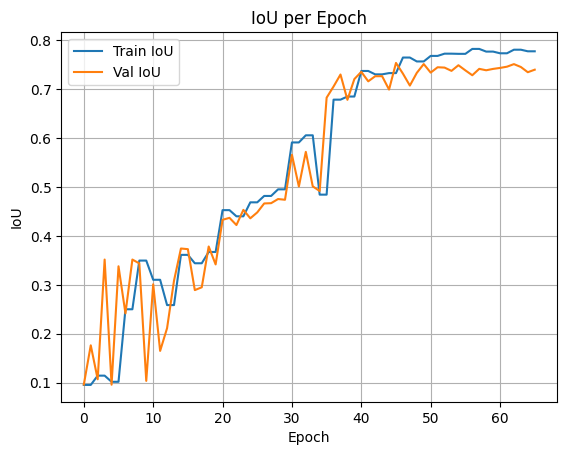

In [ ]:
# Plot training curves
plt.plot(train_ious, label="Train IoU")
plt.plot(val_ious, label="Val IoU")
plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.legend()
plt.grid()
plt.title("IoU per Epoch")
plt.show()

In [ ]:
val_eval_loader = DataLoader(
    val_dataset,
    batch_size=TRAINING_CONFIG["batch_size_val"],
    shuffle=False,
    num_workers=TRAINING_CONFIG["num_workers_val"],
    pin_memory=False,
    drop_last=False
)

model.load_state_dict(torch.load(best_model_path, map_location=device))
model.to(device)
_ = model.eval()

In [ ]:
def compute_binary_stats(pred_mask, true_mask):
    pred = pred_mask.astype(bool)
    true = true_mask.astype(bool)

    tp = np.logical_and(pred, true).sum()
    fp = np.logical_and(pred, ~true).sum()
    fn = np.logical_and(~pred, true).sum()
    tn = np.logical_and(~pred, ~true).sum()

    true_area = true.sum()
    pred_area = pred.sum()

    if true_area == 0 and pred_area == 0:
        iou = 1.0
        dice = 1.0
    else:
        iou = tp / (tp + fp + fn + 1e-8)
        dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)

    return tp, fp, fn, tn, iou, dice


val_errors = []

model.eval()

with torch.inference_mode():
    for batch_idx, batch in tqdm(enumerate(val_eval_loader), total=len(val_eval_loader)):
        x, y = batch[0].to(device), batch[1].to(device)

        with autocast(dtype=torch.float16, enabled=device.type in ["cuda", "mps"]):
            logits = model(x)
            probs = torch.sigmoid(logits)

        preds = probs > TRAINING_CONFIG["threshold"]

        for j in range(x.shape[0]):
            global_idx = batch_idx * TRAINING_CONFIG["batch_size_val"] + j

            pred_np = preds[j, 0].detach().cpu().numpy()
            true_np = y[j, 0].detach().cpu().numpy() > 0

            tp, fp, fn, tn, iou, dice = compute_binary_stats(pred_np, true_np)

            val_errors.append({
                "idx": global_idx,
                "image_path": val_dataset.df.loc[global_idx, "image_path"],
                "mask_path": val_dataset.df.loc[global_idx, "mask_path"],
                "organ": val_dataset.df.loc[global_idx, "organ"],
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "tn": tn,
                "iou": iou,
                "dice": dice,
                "true_has_mask": true_np.sum() > 0,
                "pred_has_mask": pred_np.sum() > 0,
                "pred_area": pred_np.sum(),
                "true_area": true_np.sum(),
            })

val_errors_df = pd.DataFrame(val_errors)

val_errors_df.sort_values("iou").head(20)

  0%|          | 0/43 [00:00<?, ?it/s]/tmp/ipykernel_7249/1468096202.py:31: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=torch.float16, enabled=device.type in ["cuda", "mps"]):
100%|██████████| 43/43 [00:10<00:00,  3.99it/s]


,idx,image_path,mask_path,organ,tp,fp,fn,tn,iou,dice,true_has_mask,pred_has_mask,pred_area,true_area
3,3,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,prostate,0,0,7120,255024,0.0,0.0,True,False,0,7120
77,77,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,spleen,0,27696,0,234448,0.0,0.0,False,True,27696,0
65,65,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,kidney,0,0,3990,258154,0.0,0.0,True,False,0,3990
296,296,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,lung,0,171,9970,252003,0.0,0.0,True,True,171,9970
90,90,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,prostate,0,0,13993,248151,0.0,0.0,True,False,0,13993
273,273,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,prostate,0,0,18598,243546,0.0,0.0,True,False,0,18598
272,272,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,prostate,0,0,46967,215177,0.0,0.0,True,False,0,46967
301,301,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,prostate,0,18841,160,243143,0.0,0.0,True,True,18841,160
295,295,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,lung,0,97739,0,164405,0.0,0.0,False,True,97739,0
290,290,/content/drive/MyDrive/Colab Notebooks/Hackath...,/content/drive/MyDrive/Colab Notebooks/Hackath...,lung,0,0,3219,258925,0.0,0.0,True,False,0,3219


In [ ]:
def image_to_display(img_tensor):
    img_np = img_tensor.permute(1, 2, 0).detach().cpu().numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)
    return img_np


def show_val_errors(error_df, dataset, n=6):
    rows = error_df.sort_values("iou").head(n)

    plt.figure(figsize=(12, n * 3))

    for row_i, (_, row) in enumerate(rows.iterrows()):
        idx = int(row["idx"])

        img, true_mask = dataset[idx]

        x = img.unsqueeze(0).to(device)

        model.eval()
        with torch.inference_mode():
            with autocast(dtype=torch.float16, enabled=device.type in ["cuda", "mps"]):
                logits = model(x)
                prob = torch.sigmoid(logits)[0, 0]

        pred_mask = (prob > TRAINING_CONFIG["threshold"]).detach().cpu().numpy()
        true_mask = true_mask.squeeze().detach().cpu().numpy() > 0
        img_np = image_to_display(img)

        overlay = img_np.copy()

        true_color = np.array([0.0, 1.0, 0.0])
        pred_color = np.array([1.0, 0.0, 0.0])
        alpha = 0.4

        overlay[true_mask] = (1 - alpha) * overlay[true_mask] + alpha * true_color
        overlay[pred_mask] = (1 - alpha) * overlay[pred_mask] + alpha * pred_color

        plt.subplot(n, 4, 4 * row_i + 1)
        plt.imshow(img_np)
        plt.title(f"idx={idx}, {row['organ']}")
        plt.axis("off")

        plt.subplot(n, 4, 4 * row_i + 2)
        plt.imshow(true_mask, cmap="gray")
        plt.title("True mask")
        plt.axis("off")

        plt.subplot(n, 4, 4 * row_i + 3)
        plt.imshow(pred_mask, cmap="gray")
        plt.title("Pred mask")
        plt.axis("off")

        plt.subplot(n, 4, 4 * row_i + 4)
        plt.imshow(overlay)
        plt.title(f"IoU={row['iou']:.3f}, Dice={row['dice']:.3f}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

/tmp/ipykernel_7249/2849980758.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=torch.float16, enabled=device.type in ["cuda", "mps"]):


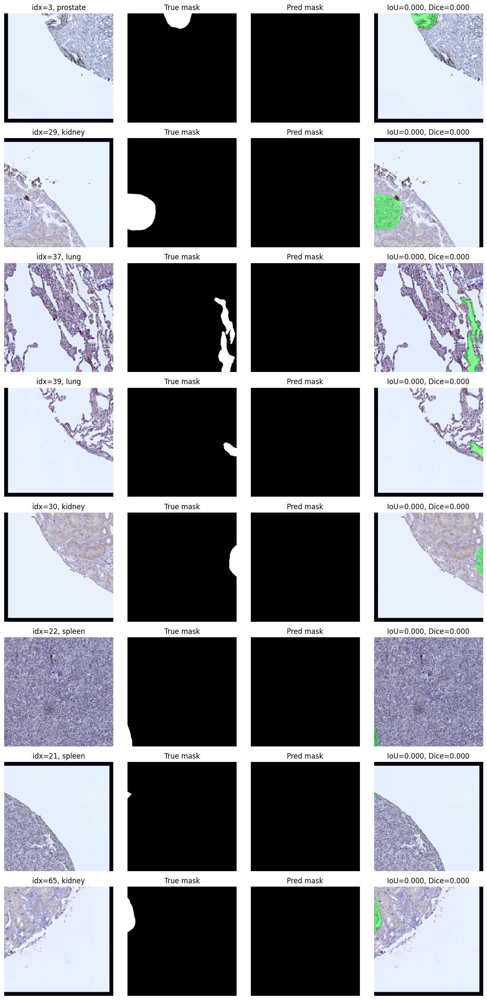

In [ ]:
# bad cases where a mask is really necessary

show_val_errors(
    val_errors_df[val_errors_df["true_has_mask"] == True],
    val_dataset,
    n=8
)

/tmp/ipykernel_7249/2849980758.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(dtype=torch.float16, enabled=device.type in ["cuda", "mps"]):


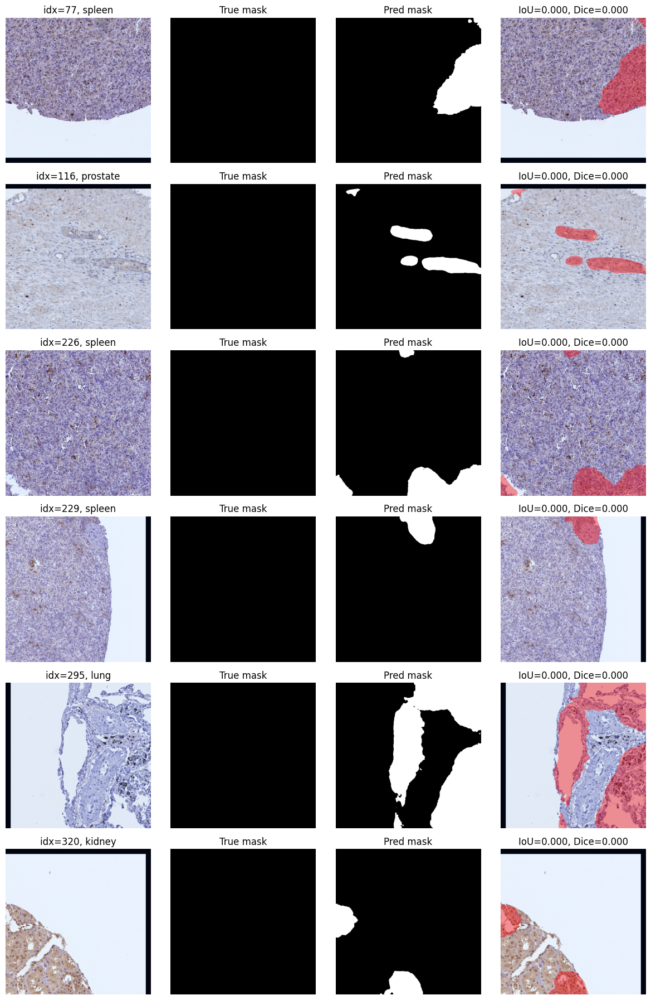

In [ ]:
# the model falsely detected a mask in an empty image

show_val_errors(
    val_errors_df[
        (val_errors_df["true_has_mask"] == False) &
        (val_errors_df["pred_has_mask"] == True)
    ],
    val_dataset,
    n=8
)

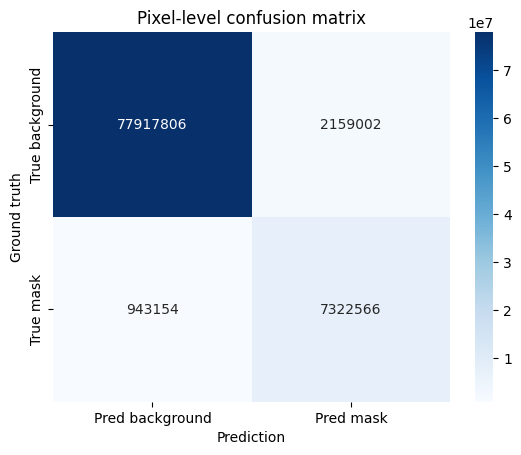

In [ ]:
tn = val_errors_df["tn"].sum()
fp = val_errors_df["fp"].sum()
fn = val_errors_df["fn"].sum()
tp = val_errors_df["tp"].sum()

pixel_cm = np.array([
    [tn, fp],
    [fn, tp]
])

sns.heatmap(
    pixel_cm,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    xticklabels=["Pred background", "Pred mask"],
    yticklabels=["True background", "True mask"]
)

plt.title("Pixel-level confusion matrix")
plt.xlabel("Prediction")
plt.ylabel("Ground truth")
plt.show()

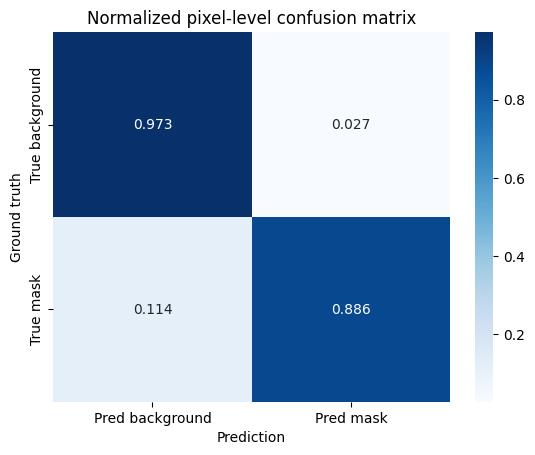

In [ ]:
pixel_cm_norm = pixel_cm / pixel_cm.sum(axis=1, keepdims=True)

sns.heatmap(
    pixel_cm_norm,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=["Pred background", "Pred mask"],
    yticklabels=["True background", "True mask"]
)

plt.title("Normalized pixel-level confusion matrix")
plt.xlabel("Prediction")
plt.ylabel("Ground truth")
plt.show()

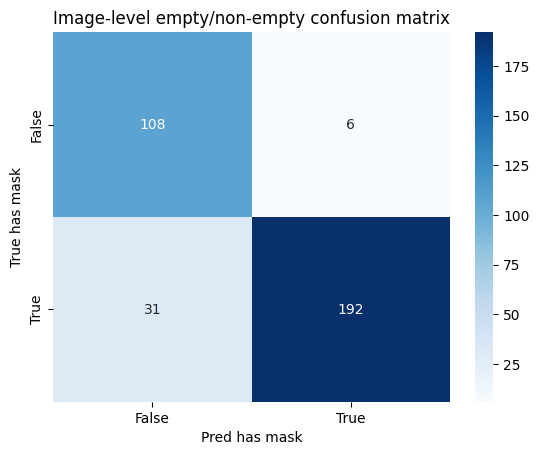

In [ ]:
image_cm = pd.crosstab(
    val_errors_df["true_has_mask"],
    val_errors_df["pred_has_mask"],
    rownames=["True has mask"],
    colnames=["Pred has mask"]
)

sns.heatmap(image_cm, annot=True, fmt="d", cmap="Blues")
plt.title("Image-level empty/non-empty confusion matrix")
plt.show()

In [ ]:
pd.crosstab(
    [val_errors_df["organ"], val_errors_df["true_has_mask"]],
    val_errors_df["pred_has_mask"],
    rownames=["organ", "true_has_mask"],
    colnames=["pred_has_mask"]
)

pred_has_mask                 False  True 
organ          true_has_mask              
kidney         False             51      1
               True               6     45
largeintestine False              5      0
               True               1     53
lung           False             19      1
               True              10     14
prostate       False              8      1
               True               8     62
spleen         False             25      3
               True               6     18

In [ ]:
organ_stats = (
    val_errors_df
    .groupby("organ")[["tp", "fp", "fn", "tn"]]
    .sum()
    .reset_index()
)

organ_stats["precision"] = organ_stats["tp"] / (organ_stats["tp"] + organ_stats["fp"] + 1e-8)
organ_stats["recall"] = organ_stats["tp"] / (organ_stats["tp"] + organ_stats["fn"] + 1e-8)
organ_stats["iou"] = organ_stats["tp"] / (organ_stats["tp"] + organ_stats["fp"] + organ_stats["fn"] + 1e-8)
organ_stats["fp_rate_bg"] = organ_stats["fp"] / (organ_stats["fp"] + organ_stats["tn"] + 1e-8)
organ_stats["fn_rate_mask"] = organ_stats["fn"] / (organ_stats["fn"] + organ_stats["tp"] + 1e-8)

display(organ_stats.sort_values("iou"))

,organ,tp,fp,fn,tn,precision,recall,iou,fp_rate_bg,fn_rate_mask
2,lung,28909,928413,149226,10427788,0.030198,0.162287,0.026125,0.081754,0.837713
4,spleen,706769,336724,132403,12455592,0.677311,0.842222,0.601047,0.026322,0.157778
3,prostate,2971711,525490,333254,16878921,0.849740,0.899166,0.775811,0.030193,0.100834
1,largeintestine,2835221,302911,262134,12066230,0.903474,0.915368,0.833823,0.024489,0.084632
0,kidney,779956,65464,66137,26089275,0.922566,0.921832,0.855631,0.002503,0.078168


In [ ]:
area_df = val_errors_df.copy()
area_df["area_ratio"] = area_df["pred_area"] / (area_df["true_area"] + 1e-8)

display(
    area_df[area_df["true_has_mask"]]
    .groupby("organ")["area_ratio"]
    .describe()
)

,count,mean,std,min,25%,50%,75%,max
organ,,,,,,,,
kidney,51.0,0.902965,0.358200,0.0,0.914552,1.019954,1.076365,1.576257
largeintestine,54.0,1.007258,0.268226,0.0,0.973464,1.016093,1.046431,2.047181
lung,24.0,20.229198,54.406486,0.0,0.000000,0.090838,20.793746,261.529973
prostate,70.0,3.109374,14.305091,0.0,0.924649,1.024675,1.085943,117.756250
spleen,24.0,0.976661,0.694616,0.0,0.636176,1.054248,1.266290,2.464926


In [ ]:
empty_fp = val_errors_df[val_errors_df["true_has_mask"] == False].copy()

display(
    empty_fp
    .groupby("organ")["pred_area"]
    .describe()
)

display(
    empty_fp[empty_fp["pred_has_mask"]]
    [["idx", "organ", "image_path", "pred_area", "true_area", "iou"]]
    .sort_values(["organ", "pred_area"], ascending=[True, False])
)

,count,mean,std,min,25%,50%,75%,max
organ,,,,,,,,
kidney,52.0,282.557692,2037.552496,0.0,0.0,0.0,0.0,14693.0
largeintestine,5.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
lung,20.0,4886.950000,21855.104805,0.0,0.0,0.0,0.0,97739.0
prostate,9.0,1910.222222,5730.666667,0.0,0.0,0.0,0.0,17192.0
spleen,28.0,2186.750000,7032.737177,0.0,0.0,0.0,0.0,27696.0


,idx,organ,image_path,pred_area,true_area,iou
320,320,kidney,/content/drive/MyDrive/Colab Notebooks/Hackath...,14693,0,0.0
295,295,lung,/content/drive/MyDrive/Colab Notebooks/Hackath...,97739,0,0.0
116,116,prostate,/content/drive/MyDrive/Colab Notebooks/Hackath...,17192,0,0.0
77,77,spleen,/content/drive/MyDrive/Colab Notebooks/Hackath...,27696,0,0.0
226,226,spleen,/content/drive/MyDrive/Colab Notebooks/Hackath...,25133,0,0.0
229,229,spleen,/content/drive/MyDrive/Colab Notebooks/Hackath...,8400,0,0.0


Это не foreground pressure. Это почти полный провал по лёгким: модель в 91% mask pixels даёт background. При этом area_ratio у lung странный: median 0.02, 25% 0, 75% 1.95, max 8.65. То есть она то почти ничего не рисует, то рисует сильно мимо. Это очень похоже на проблему неоднозначной/шумной разметки или на то, что lung сильно отличается визуально от остальных органов.

prostate:
recall 0.98, precision 0.84, fp_rate_bg 0.053
area_ratio mean 1.22. модель почти не пропускает prostate-маски, но фон чаще превращает в foreground, чем у kidney/spleen/lung. Плюс на пустых prostate есть крупные FP: 15916, 5242.

spleen:
recall 0.90, precision 0.65
area_ratio mean 1.16

Тут тоже есть FP на пустых: 15616, 5852, 3464, 2005. Но выборка маленькая: всего 8 true-positive spleen и 18 empty spleen, поэтому вывод осторожный.

kidney / largeintestine:
всё нормально

In [ ]:
with torch.amp.autocast(device_type='cuda' if device.type == 'cuda' else 'cpu'):
    with torch.inference_mode():
        pred = model(x.float().to(device))

In [ ]:
pred = pred.detach().cpu().numpy()

Min/max Predictions:  -4.049333 3.0047727


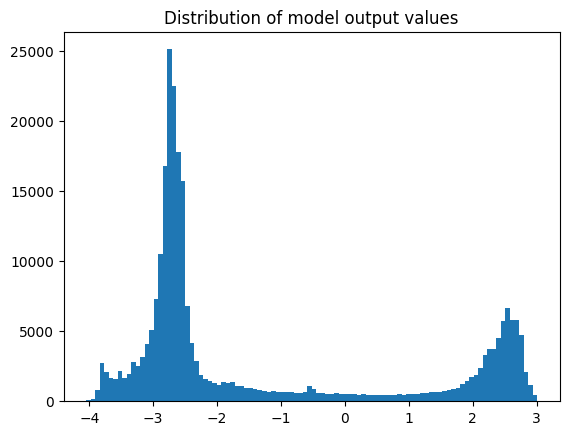

In [ ]:
# Preparing a batch
x, y = next(iter(val_loader))
x = x.to(device)
with torch.no_grad():
    out = model(x)

# Check values of output tensor
out_cpu = out[0].detach().cpu().squeeze().numpy()

# Show range of values on histogram
print("Min/max Predictions: ", out_cpu.min(), out_cpu.max())
plt.hist(out_cpu.flatten(), bins=100)
plt.title("Distribution of model output values")
plt.show()

In [ ]:
class SegmentationDatasetSubmit(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "image_path"]
        slice_id = self.df.loc[idx, "slice_id"]

        image = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image=image)["image"]

        return image, slice_id

In [ ]:
test_fold = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/test/test.csv")

In [ ]:
test_fold.head()

,id,organ,data_source,img_height,img_width,pixel_size,tissue_thickness,age,sex,image_path,slice_id
0,10044,prostate,HPA,512,512,0.4,4,37.0,Male,test/10044_0004.png,10044_0004
1,10044,prostate,HPA,512,512,0.4,4,37.0,Male,test/10044_0007.png,10044_0007
2,10044,prostate,HPA,512,512,0.4,4,37.0,Male,test/10044_0001.png,10044_0001
3,10044,prostate,HPA,512,512,0.4,4,37.0,Male,test/10044_0002.png,10044_0002
4,10044,prostate,HPA,512,512,0.4,4,37.0,Male,test/10044_0003.png,10044_0003


In [ ]:
test_fold['image_path'] = test_fold['image_path'].str.replace('test/', '/content/drive/MyDrive/Colab Notebooks/Hackathon OpenBio/test/test/')

In [ ]:
test_dataset = SegmentationDatasetSubmit(dataframe=test_fold, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=TRAINING_CONFIG['batch_size_test'], shuffle=False, num_workers=TRAINING_CONFIG['num_workers_test'])

In [ ]:
def rle_encode(mask: np.ndarray) -> str:
    """
    Convert a 2‑D binary mask to the Kaggle run‑length encoding format.

    Parameters
    ----------
    mask : np.ndarray
        2‑D array of type bool, int, or uint8 where non‑zero pixels are foreground.

    Returns
    -------
    str
        Space‑separated "start length start length ..." string.
        An empty string is returned when the mask is empty.

    Notes
    -----
    • Pixels are enumerated column‑wise with 1‑based indexing.
    • The function tolerates non‑boolean dtypes by thresholding `>0`.
    """
    if mask.ndim != 2:
        raise ValueError("Input mask must be 2‑D")

    # Convert to 1‑D column‑major vector of 0 and 1
    pixels = (mask > 0).T.flatten()        # transpose then flatten (C order) == flatten(order="F")

    if pixels.sum() == 0:
        return "0"                          # empty mask

    # Pad zeros at both ends to catch runs that start or end at image borders
    padded = np.concatenate([[0], pixels, [0]])
    changes = np.where(padded[1:] != padded[:-1])[0] + 1   # indices where value flips

    runs = changes[1::2] - changes[0::2]                   # run lengths
    starts = changes[0::2]                                 # 1‑based already

    rle = np.column_stack((starts, runs)).flatten()
    return " ".join(str(x) for x in rle)

In [ ]:
submission = {"id": [], "rle_mask": []}

In [ ]:
# Load best model
model.load_state_dict(torch.load(best_model_path, map_location=device))

<All keys matched successfully>

In [ ]:
print("Starting inference on test set...")
model.eval()
for data in tqdm(test_loader):
    x = data[0].to(device).float()
    slice_id = data[1]

    with torch.inference_mode():
        with torch.amp.autocast(device_type='cuda' if device.type == 'cuda' else 'cpu'):
            ypred = torch.sigmoid(model(x))

    for i in range(ypred.shape[0]):
        pred_mask = (ypred[i, 0] > TRAINING_CONFIG['threshold']).detach().cpu().numpy()
        rle_mask = rle_encode(pred_mask)
        submission["id"].append(slice_id[i])
        submission["rle_mask"].append(rle_mask)

Starting inference on test set...


100%|██████████| 144/144 [09:35<00:00,  4.00s/it]


In [ ]:
pd.DataFrame(submission)

,id,rle_mask
0,10044_0004,1 414 447 480 959 480 1471 480 1983 480 2495 4...
1,10044_0007,1 188 513 188 1025 188 1537 188 2049 188 2561 ...
2,10044_0001,248 207 485 28 761 206 997 28 1273 206 1509 28...
3,10044_0002,253 174 765 175 1278 174 1790 174 2302 174 281...
4,10044_0003,84228 5 84722 28 85211 58 85713 74 86219 86 86...
...,...,...
1146,9769_0000,0
1147,9769_0002,0
1148,9769_0006,0
1149,9769_0005,0


In [ ]:
pd.DataFrame(submission).to_csv("submission_besedina.csv", index=False)

In [ ]:
print("Saved submission file")

Saved submission file


In [ ]:
kaggle_token = {
    "username": userdata.get("KAGGLE_USERNAME"),
    "key": userdata.get("KAGGLE_KEY"),
}

os.makedirs("/root/.kaggle", exist_ok=True)

with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_token, f)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

# Submit to Kaggle using shell command for Colab

submit_message = (
    f"{timestamp} | "
    f"model={TRAINING_CONFIG['model_name']} | "
    f"encoder={TRAINING_CONFIG['encoder_name']} | "
    f"weights={TRAINING_CONFIG['encoder_weights']}"
)

print(submit_message)

!kaggle competitions submit \
    -c open-bio-2026-final-project \
    -f submission_besedina.csv \
    -m "$submit_message"

2026-06-29_20-55-26 | model=Segformer | encoder=mit_b2 | weights=imagenet
100% 3.36M/3.36M [00:02<00:00, 1.52MB/s]
Successfully submitted to OpenBio 2026 final project

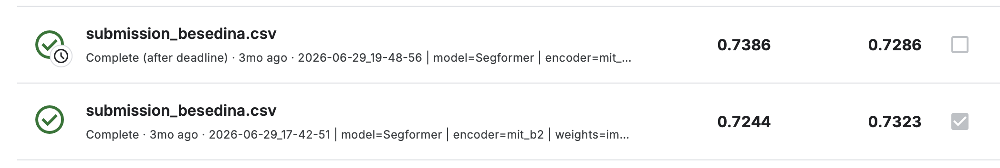